# Week 2 Visual Synthesis

This notebook translates the Week 2 SQL analysis into a small set of decision-focused visuals covering marketplace growth, category economics, customer value, and two-sided marketplace concentration.

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

## Customer vs Seller Merchandise Value Concentration

**Question:** Is recorded merchandise value more concentrated on the customer side or the seller side?

**Finding:** Seller-side merchandise value is substantially more concentrated than customer-side merchandise value.

In [36]:
df = pd.DataFrame({
    "cutoff": ["Top 1%", "Top 5%", "Top 10%"],
    "Customers": [11.53, 29.26, 41.25],
    "Sellers": [26.07, 53.30, 67.56]
})

df

,cutoff,Customers,Sellers
0,Top 1%,11.53,26.07
1,Top 5%,29.26,53.30
2,Top 10%,41.25,67.56


### Data QA

Confirm the plotting dataset has the expected data types and contains no missing values before visualization.

In [37]:
df.dtypes

cutoff           str
Customers    float64
Sellers      float64
dtype: object

In [38]:
df.isna().sum()

cutoff       0
Customers    0
Sellers      0
dtype: int64

### Final Visualization

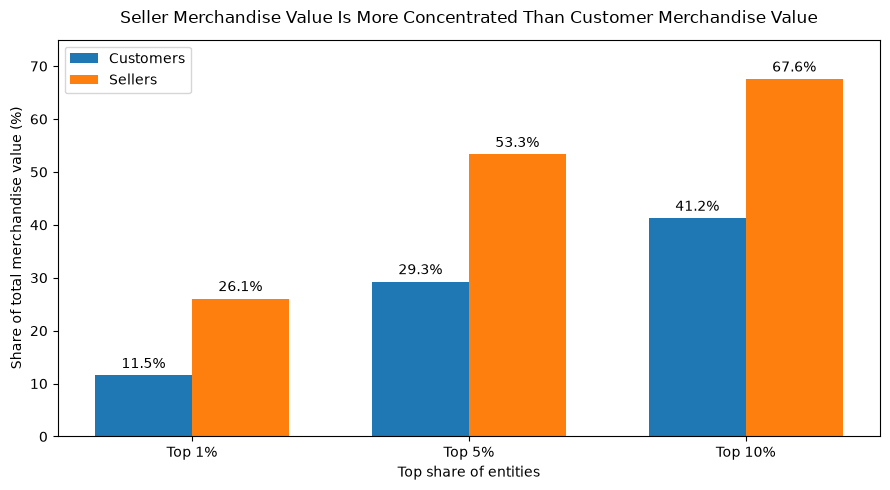

In [39]:
x = np.arange(len(df["cutoff"]))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars_customers = ax.bar(
    x - width / 2,
    df["Customers"],
    width,
    label="Customers"
)

bars_sellers = ax.bar(
    x + width / 2,
    df["Sellers"],
    width,
    label="Sellers"
)

ax.set_title(
    "Seller Merchandise Value Is More Concentrated Than Customer Merchandise Value",
    pad=12
)

ax.set_xlabel("Top share of entities")
ax.set_ylabel("Share of total merchandise value (%)")

ax.set_xticks(x)
ax.set_xticklabels(df["cutoff"])

ax.legend()

ax.bar_label(
    bars_customers,
    fmt="%.1f%%",
    padding=3
)

ax.bar_label(
    bars_sellers,
    fmt="%.1f%%",
    padding=3
)

ax.set_ylim(0, 75)

plt.tight_layout()

fig.savefig(
    "../visuals/customer_vs_seller_revenue_concentration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

Recorded merchandise value is materially more concentrated among sellers than among customers.

The top 10% of sellers account for approximately 67.6% of recorded merchandise value, compared with approximately 41.2% for the top 10% of customers.

This suggests stronger supply-side concentration within the marketplace, although the result is descriptive and does not establish causal seller dependency.

## Repeat Customer Economics

**Question:** Why are repeat customers more valuable than one-time customers?

**Finding:** Repeat customers generate substantially more recorded merchandise value per customer despite lower average order value, indicating that the value difference is primarily frequency-driven.

In [40]:
df_repeat = pd.DataFrame({
    "customer_type": ["One-Time", "Repeat"],
    "Merchandise value per customer": [138.67, 262.03],
    "Average customer AOV": [138.67, 123.98]
})

df_repeat

,customer_type,Merchandise value per customer,Average customer AOV
0,One-Time,138.67,138.67
1,Repeat,262.03,123.98


### Data QA

Confirm the plotting dataset has the expected data types and no missing values.

In [41]:
df_repeat.dtypes

customer_type                         str
Merchandise value per customer    float64
Average customer AOV              float64
dtype: object

In [42]:
df_repeat.isna().sum()

customer_type                     0
Merchandise value per customer    0
Average customer AOV              0
dtype: int64

### Final Visualization

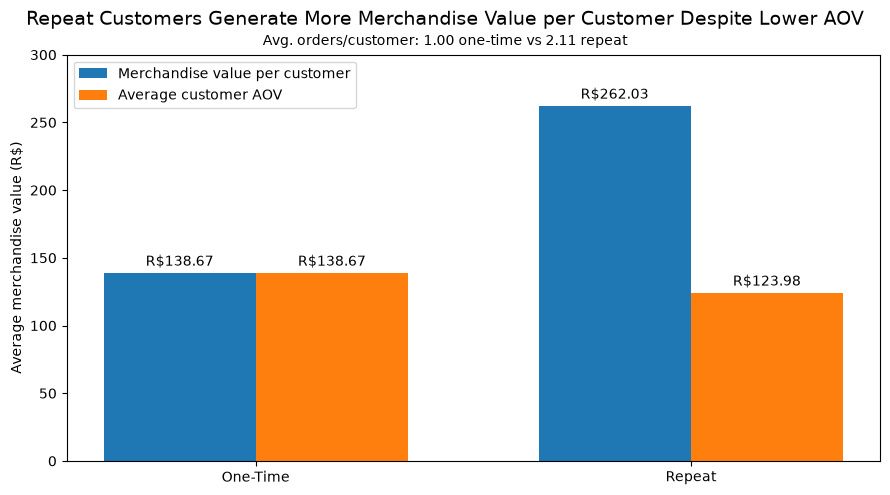

In [43]:
x = np.arange(len(df_repeat["customer_type"]))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars_revenue_per_customer = ax.bar(
    x - width / 2,
    df_repeat["Merchandise value per customer"],
    width,
    label="Merchandise value per customer"
)

bars_average_customer_aov = ax.bar(
    x + width / 2,
    df_repeat["Average customer AOV"],
    width,
    label="Average customer AOV"
)

fig.suptitle(
    "Repeat Customers Generate More Merchandise Value per Customer Despite Lower AOV",
    fontsize=14,
    y=0.98
)

fig.text(
    0.5,
    0.91,
    "Avg. orders/customer: 1.00 one-time vs 2.11 repeat",
    ha="center",
    fontsize=10
)

ax.set_ylabel("Average merchandise value (R$)")
ax.set_xticks(x)
ax.set_xticklabels(df_repeat["customer_type"])
ax.legend()

ax.bar_label(
    bars_revenue_per_customer,
    fmt="R$%.2f",
    padding=3
)

ax.bar_label(
    bars_average_customer_aov,
    fmt="R$%.2f",
    padding=3
)

ax.set_ylim(0, 300)

plt.tight_layout()

fig.savefig(
    "../visuals/repeat_vs_one_time_customer_economics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

Repeat customers generate approximately R$262 in recorded merchandise value per customer compared with approximately R$139 for one-time customers.

Their average order value is lower, not higher. The customer-value difference is therefore primarily explained by higher purchase frequency rather than larger individual orders.

## Customer Merchandise Value Distribution

**Question:** How unevenly is recorded merchandise value distributed across customers?

**Finding:** Customer merchandise value is highly right-skewed, meaning the mean is not representative of the typical customer.

In [44]:
df_customer_revenue = pd.read_csv(
    "../data/processed/customer_revenue_distribution.csv"
)

df_customer_revenue

,customer_id,total_customer_revenue
0,d80730c15c647bc8f2ad77c908ba5ca9,0.85
1,b38211bd797f4fdd81a98b9d1754b606,0.85
2,317cfc692e3f86c45c95697c61c853a6,2.20
3,bd06ce0e06ad77a7f681f1a4960a3cc6,2.29
4,cf3839da0d9492ad151690b65f45d800,2.99
...,...,...
95415,459bef486812aa25204be022145caa62,6729.00
95416,dc4802a71eae9be1dd28f5d788ceb526,6735.00
95417,763c8b1c9c68a0229c42c9fc6f662b93,7160.00
95418,da122df9eeddfedc1dc1f5349a1a690c,7388.00


### Data QA

Confirm the customer-level merchandise-value dataset has the expected data types, no missing values, one row per customer, and distribution statistics consistent with the SQL analysis.

In [45]:
df_customer_revenue.dtypes

customer_id                   str
total_customer_revenue    float64
dtype: object

In [46]:
df_customer_revenue.isna().sum()

customer_id               0
total_customer_revenue    0
dtype: int64

In [47]:
df_customer_revenue["customer_id"].nunique()

95420

In [48]:
df_customer_revenue["total_customer_revenue"].describe(
    percentiles=[0.5, 0.75, 0.90, 0.95]
)

count    95420.000000
mean       142.440198
std        217.656355
min          0.850000
50%         89.900000
75%        155.000000
90%        284.000000
95%        422.000000
max      13440.000000
Name: total_customer_revenue, dtype: float64

### Final Visualization

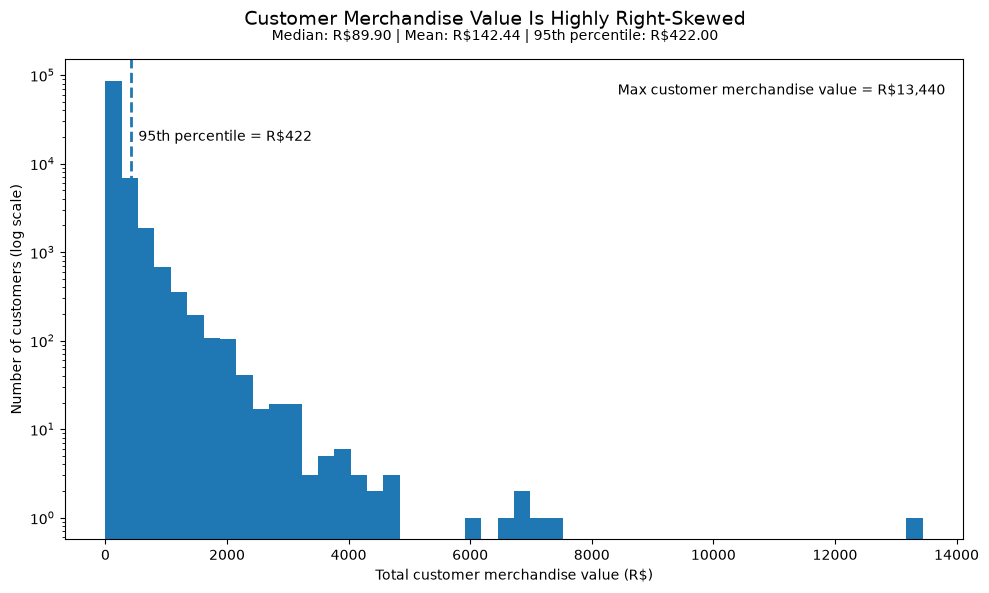

In [49]:
revenue = df_customer_revenue["total_customer_revenue"]

median_rev = revenue.median()
mean_rev = revenue.mean()
p95_rev = revenue.quantile(0.95)
max_rev = revenue.max()

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    revenue,
    bins=50
)

ax.set_yscale("log")

ax.axvline(
    p95_rev,
    linestyle="--",
    linewidth=2
)

fig.suptitle(
    "Customer Merchandise Value Is Highly Right-Skewed",
    fontsize=14,
    y=0.98
)

fig.text(
    0.5,
    0.93,
    f"Median: R${median_rev:.2f} | Mean: R${mean_rev:.2f} | 95th percentile: R${p95_rev:.2f}",
    ha="center",
    fontsize=10
)

ax.set_xlabel("Total customer merchandise value (R$)")
ax.set_ylabel("Number of customers (log scale)")

ax.text(
    p95_rev + 120,
    2e4,
    f"95th percentile = R${p95_rev:.0f}",
    ha="left",
    va="center"
)

ax.text(
    0.98,
    0.95,
    f"Max customer merchandise value = R${max_rev:,.0f}",
    transform=ax.transAxes,
    ha="right",
    va="top"
)

plt.tight_layout(rect=[0, 0, 1, 0.98])

fig.savefig(
    "../visuals/customer_revenue_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

Customer merchandise value is strongly right-skewed. The median customer merchandise value is substantially below the mean, while a small upper tail reaches much higher values.

This heterogeneity supports later segmentation rather than treating the customer base as economically uniform.

## Product Category Economics

**Question:** How do product categories differ in the combination of sales volume and average item value?

**Finding:** Categories occupy meaningfully different volume-value positions, so merchandise-value rankings alone do not fully explain category economics.

In [50]:
df_category = pd.read_csv(
    "../data/processed/category_performance.csv"
)

df_category

,product_category,revenue,distinct_order_volume,items_sold,average_item_value,revenue_share
0,cama_mesa_banho,1036988.68,9417,11115,93.296327,7.63
1,beleza_saude,1258681.34,8836,9670,130.163531,9.26
2,esporte_lazer,988048.97,7720,8641,114.344285,7.27
3,moveis_decoracao,729762.49,6449,8334,87.564494,5.37
4,informatica_acessorios,911954.32,6689,7827,116.513903,6.71
...,...,...,...,...,...,...
69,cds_dvds_musicais,730.00,12,14,52.142857,0.01
70,la_cuisine,2054.99,13,14,146.785000,0.02
71,pc_gamer,1545.95,8,9,171.772222,0.01
72,fashion_roupa_infanto_juvenil,569.85,8,8,71.231250,0.00


### Data QA

Confirm the category-level dataset has the expected data types, one row per category, and plausible ranges for items sold, average item value, and recorded merchandise value.

In [51]:
df_category.dtypes

product_category             str
revenue                  float64
distinct_order_volume      int64
items_sold                 int64
average_item_value       float64
revenue_share            float64
dtype: object

In [52]:
df_category.isna().sum()

product_category         1
revenue                  0
distinct_order_volume    0
items_sold               0
average_item_value       0
revenue_share            0
dtype: int64

In [53]:
df_category["product_category"].nunique()

73

In [54]:
df_category[[
    "items_sold",
    "average_item_value",
    "revenue"
]].describe()

,items_sold,average_item_value,revenue
count,74.000000,74.000000,7.400000e+01
mean,1522.297297,146.319397,1.836709e+05
std,2564.979835,145.237947,2.989467e+05
min,2.000000,25.342333,2.832900e+02
25%,77.750000,82.534288,7.846512e+03
50%,279.500000,114.646880,4.659262e+04
75%,1669.000000,152.810694,1.912863e+05
max,11115.000000,1098.340542,1.258681e+06


In [55]:
highlight_categories = [
    "beleza_saude",
    "cama_mesa_banho",
    "relogios_presentes",
    "pcs",
    "telefonia"
]

In [56]:
df_category[
    df_category["product_category"].isin(highlight_categories)
][[
    "product_category",
    "items_sold",
    "average_item_value",
    "revenue"
]]

,product_category,items_sold,average_item_value,revenue
0,cama_mesa_banho,11115,93.296327,1036988.68
1,beleza_saude,9670,130.163531,1258681.34
6,relogios_presentes,5991,201.135984,1205005.68
7,telefonia,4545,71.213978,323667.53
46,pcs,203,1098.340542,222963.13


### Final Visualization

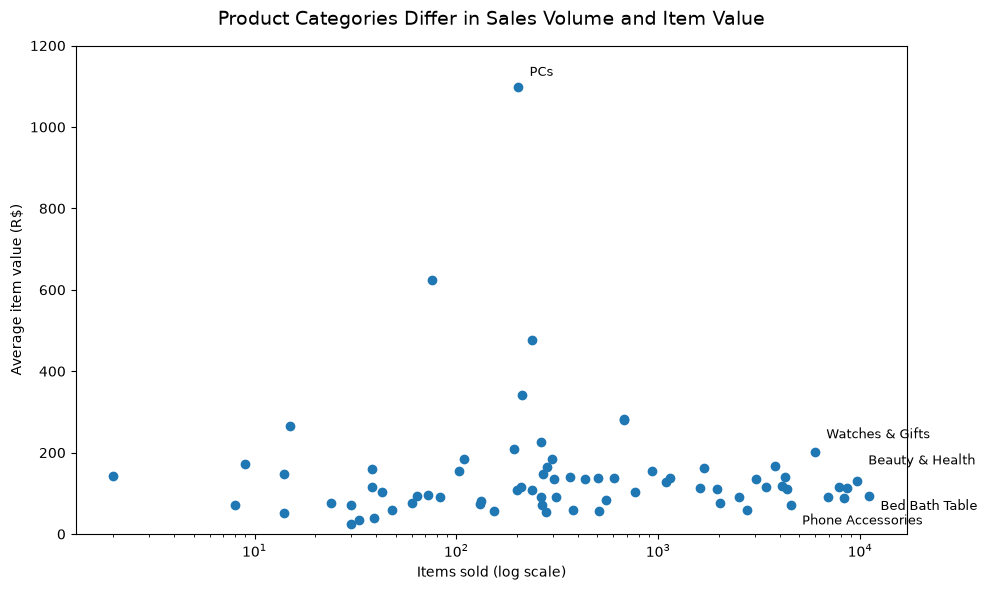

In [57]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    df_category["items_sold"],
    df_category["average_item_value"]
)

ax.set_xscale("log")
ax.set_ylim(0, 1200)

ax.set_xlabel("Items sold (log scale)")
ax.set_ylabel("Average item value (R$)")

ax.set_title(
    "Product Categories Differ in Sales Volume and Item Value",
    fontsize=14,
    pad=15
)

display_names = {
    "beleza_saude": "Beauty & Health",
    "cama_mesa_banho": "Bed Bath Table",
    "relogios_presentes": "Watches & Gifts",
    "pcs": "PCs",
    "telefonia": "Phone Accessories"
}

label_offsets = {
    "beleza_saude": (8, 12),
    "cama_mesa_banho": (8, -10),
    "relogios_presentes": (8, 10),
    "pcs": (8, 8),
    "telefonia": (8, -14)
}

for category in highlight_categories:
    row = df_category[
        df_category["product_category"] == category
    ].iloc[0]

    ax.annotate(
        display_names[category],
        (row["items_sold"], row["average_item_value"]),
        xytext=label_offsets[category],
        textcoords="offset points",
        fontsize=9
    )

plt.tight_layout()

fig.savefig(
    "../visuals/category_volume_value_drivers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

Product categories generate marketplace value through different economic profiles. Bed Bath Table and Beauty & Health are volume-driven, while Watches & Gifts combines meaningful volume with higher item value.

PCs represents the opposite extreme: very low volume but exceptionally high average item value. This demonstrates why category performance cannot be understood through merchandise-value rankings alone.

## Marketplace Growth Mechanics

**Question:** What is driving growth in recorded marketplace merchandise value over time?

**Finding:** Merchandise value closely tracks order volume, while average order value remains comparatively stable.

### Data QA

Confirm the monthly dataset has the expected data types, convert `month` to datetime, exclude incomplete edge months, and verify the indexed merchandise-value and order-volume series contain no missing values.

In [58]:
df_monthly = pd.read_csv(
    "../data/processed/monthly_business_performance.csv"
)

df_monthly

,month,order_volume,revenue,average_order_value,previous_month_average_order_value,average_order_value_percentage_change
0,2016-09-01 00:00:00,3,267.36,89.12,NaN,NaN
1,2016-10-01 00:00:00,308,49507.66,160.74,89.12,80.36
2,2016-12-01 00:00:00,1,10.90,10.90,160.74,-93.22
3,2017-01-01 00:00:00,789,120312.87,152.49,10.90,1298.97
4,2017-02-01 00:00:00,1733,247303.02,142.70,152.49,-6.42
5,2017-03-01 00:00:00,2641,374344.30,141.74,142.70,-0.67
6,2017-04-01 00:00:00,2391,359927.23,150.53,141.74,6.20
7,2017-05-01 00:00:00,3660,506071.14,138.27,150.53,-8.15
8,2017-06-01 00:00:00,3217,433038.60,134.61,138.27,-2.65
9,2017-07-01 00:00:00,3969,498031.48,125.48,134.61,-6.78


In [59]:
df_monthly.dtypes

month                                        str
order_volume                               int64
revenue                                  float64
average_order_value                      float64
previous_month_average_order_value       float64
average_order_value_percentage_change    float64
dtype: object

In [60]:
df_monthly["month"] = pd.to_datetime(df_monthly["month"])

In [61]:
df_monthly.dtypes

month                                    datetime64[us]
order_volume                                      int64
revenue                                         float64
average_order_value                             float64
previous_month_average_order_value              float64
average_order_value_percentage_change           float64
dtype: object

In [62]:
df_monthly_chart = df_monthly[
    (df_monthly["month"] >= "2017-01-01") &
    (df_monthly["month"] <= "2018-08-01")
].copy()

df_monthly_chart

,month,order_volume,revenue,average_order_value,previous_month_average_order_value,average_order_value_percentage_change
3,2017-01-01,789,120312.87,152.49,10.90,1298.97
4,2017-02-01,1733,247303.02,142.70,152.49,-6.42
5,2017-03-01,2641,374344.30,141.74,142.70,-0.67
6,2017-04-01,2391,359927.23,150.53,141.74,6.20
7,2017-05-01,3660,506071.14,138.27,150.53,-8.15
8,2017-06-01,3217,433038.60,134.61,138.27,-2.65
9,2017-07-01,3969,498031.48,125.48,134.61,-6.78
10,2017-08-01,4293,573971.68,133.70,125.48,6.55
11,2017-09-01,4243,624401.69,147.16,133.70,10.07
12,2017-10-01,4568,664219.43,145.41,147.16,-1.19


In [63]:
df_monthly_chart = df_monthly_chart[
    [
        "month",
        "order_volume",
        "revenue",
        "average_order_value"
    ]
]

In [64]:
baseline_revenue = df_monthly_chart.iloc[0]["revenue"]
baseline_orders = df_monthly_chart.iloc[0]["order_volume"]

baseline_revenue, baseline_orders

(np.float64(120312.87), np.int64(789))

In [65]:
df_monthly_chart["revenue_index"] = (
    df_monthly_chart["revenue"] / baseline_revenue * 100
)

df_monthly_chart["order_volume_index"] = (
    df_monthly_chart["order_volume"] / baseline_orders * 100
)

In [66]:
df_monthly_chart

,month,order_volume,revenue,average_order_value,revenue_index,order_volume_index
3,2017-01-01,789,120312.87,152.49,100.000000,100.000000
4,2017-02-01,1733,247303.02,142.70,205.549930,219.645120
5,2017-03-01,2641,374344.30,141.74,311.142357,334.727503
6,2017-04-01,2391,359927.23,150.53,299.159375,303.041825
7,2017-05-01,3660,506071.14,138.27,420.629264,463.878327
8,2017-06-01,3217,433038.60,134.61,359.927080,407.731305
9,2017-07-01,3969,498031.48,125.48,413.946970,503.041825
10,2017-08-01,4293,573971.68,133.70,477.065903,544.106464
11,2017-09-01,4243,624401.69,147.16,518.981627,537.769328
12,2017-10-01,4568,664219.43,145.41,552.076789,578.960710


In [67]:
df_monthly_chart[
    ["revenue_index", "order_volume_index"]
].isna().sum()

revenue_index         0
order_volume_index    0
dtype: int64

### Final Visualization

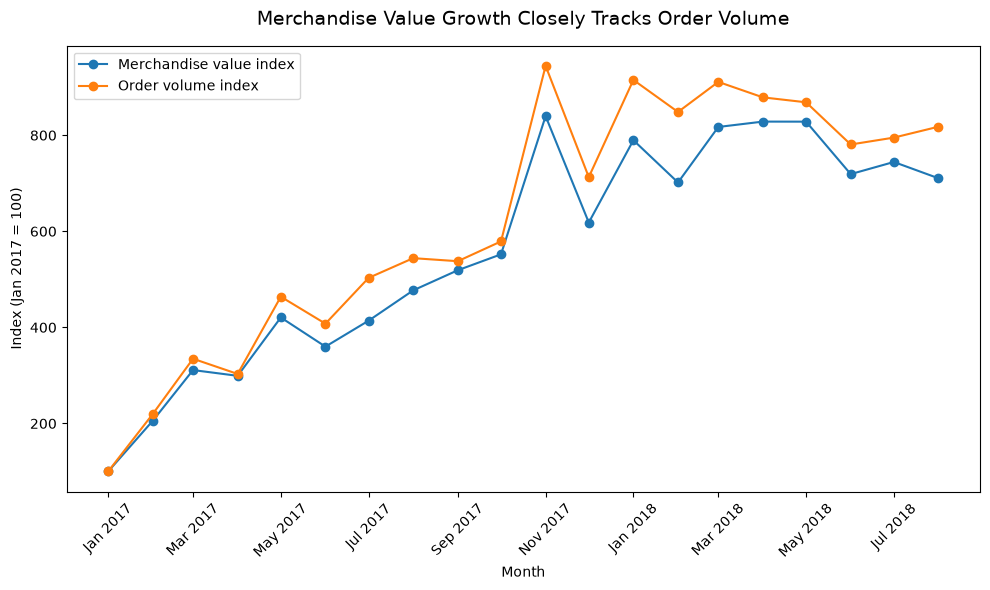

In [68]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    df_monthly_chart["month"],
    df_monthly_chart["revenue_index"],
    marker="o",
    label="Merchandise value index"
)

ax.plot(
    df_monthly_chart["month"],
    df_monthly_chart["order_volume_index"],
    marker="o",
    label="Order volume index"
)

ax.set_title(
    "Merchandise Value Growth Closely Tracks Order Volume",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Month")
ax.set_ylabel("Index (Jan 2017 = 100)")

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=2)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.xticks(rotation=45)

ax.legend()

plt.tight_layout()

fig.savefig(
    "../visuals/monthly_revenue_vs_order_volume.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

Recorded merchandise value and order volume follow similar trajectories across the reliable monthly observation window.

Order volume generally grows faster relative to the January 2017 baseline, while average order value remains comparatively stable. This indicates that observed marketplace merchandise-value growth was primarily associated with increasing transaction volume rather than sustained increases in order value.